In [99]:
import pandas as pd 
import matplotlib.pyplot as plt

# 1. Análise Exploratória dos dados (EDA)

In [100]:
treino = pd.read_csv("../../data/Q1_training.csv")
treino

,x1,x2,y
0,1.370958,2.325058,1
1,-0.564698,0.524122,0
2,0.363128,0.970733,0
3,0.632863,0.376973,0
4,0.404268,-0.995933,0
...,...,...,...
995,0.582972,-0.540609,0
996,-0.986567,0.259451,0
997,1.684622,-1.178279,1
998,-1.366841,0.306138,1


In [101]:
print("Métricas estatísticas padrão: \n")
treino.describe()

Métricas estatísticas padrão: 



,x1,x2,y
count,1000.000000,1000.000000,1000.000000
mean,-0.025824,-0.005318,0.595000
std,1.002521,0.986061,0.491138
min,-3.371739,-2.928477,0.000000
25%,-0.675461,-0.666813,0.000000
50%,-0.013134,-0.010602,1.000000
75%,0.664005,0.658376,1.000000
max,3.495304,3.584659,1.000000


In [102]:
classe_1 = int(treino["y"].value_counts()[1])
classe_0 = int(treino["y"].value_counts()[0])

print("Desbalanceamento de classes\n")

print("Número de amostras com y = 1: ", classe_1)
print(f"Esae número representa: {(classe_1/(classe_1+classe_0))*100:.2f}% do total")

print("\n")
print("Número de amostras com y = 0: ", classe_0)
print(f"Esae número representa: {(classe_0/(classe_1+classe_0))*100:.2f}% do total")


Desbalanceamento de classes

Número de amostras com y = 1:  595
Esae número representa: 59.50% do total


Número de amostras com y = 0:  405
Esae número representa: 40.50% do total


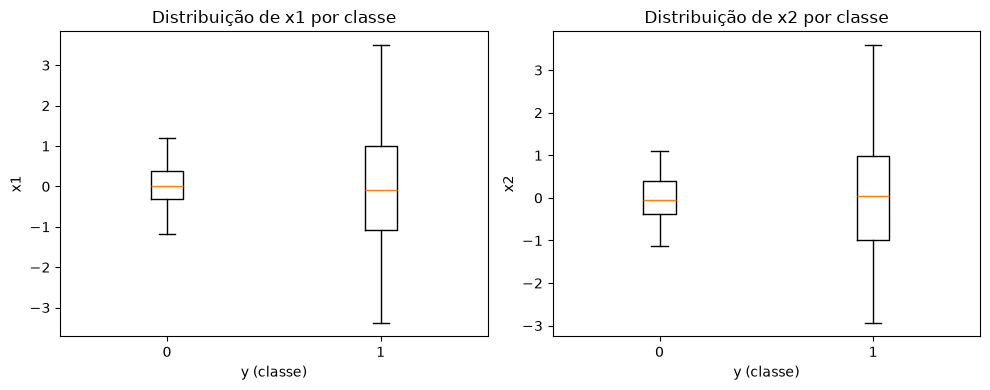

In [103]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, ["x1", "x2"]):
    
    ax.boxplot([treino.loc[treino["y"] == 0, col], treino.loc[treino["y"] == 1, col]], tick_labels=["0", "1"])
    
    ax.set_xlabel("y (classe)")
    ax.set_ylabel(col)

    ax.set_title(f"Distribuição de {col} por classe")

plt.tight_layout()
plt.show()



# 2. Etapa de Treino

In [104]:
X_treino = treino.drop(columns=["y"])
y_treino = treino["y"]

## 2.1 Regressão Logística:

In [105]:
from sklearn.linear_model import LogisticRegression

logit = LogisticRegression(penalty=None) 
logit.fit(X_treino, y_treino)


/home/iran-honorato/Área de trabalho/BCC Insper/5º semestre/Modelagem Preditiva/modelagem-preditiva-aps/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",None
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects

## 2.2 Árvore de Decisão:

In [106]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(criterion="entropy", random_state=42)
decision_tree.fit(X_treino, y_treino)


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samp

# 3. Etapa de Teste

In [107]:
teste = pd.read_csv("../../data/Q1_test.csv")

X_teste = teste.drop(columns=["y"])
y_teste = teste["y"]

## 3.1 Regressão Logística

In [108]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, roc_auc_score, RocCurveDisplay

# Calcula as probabilidades de cada amostra para a classe 1
prob = logit.predict_proba(X_teste)[:, 1]

# Definindo o corte (threshold) como 0.5
threshold = 0.5
classificador_logit = (prob >= threshold).astype(int)


In [109]:
print("Matriz de Confusão")
print(confusion_matrix(y_teste, classificador_logit))

print("\n")

print("Acurácia:", accuracy_score(y_teste, classificador_logit))

# Precision: dos que o modelo previu como 1, quantos realmente são 1 -> VP / (VP + FP)
print("Precision:", precision_score(y_teste, classificador_logit, zero_division=0))

# Recall (sensibilidade): dos que realmente são 1, quantos o modelo acertou -> VP / (VP + FN)
print("Recall:", recall_score(y_teste, classificador_logit, zero_division=0))



Matriz de Confusão
[[  0 388]
 [  0 612]]


Acurácia: 0.612
Precision: 0.612
Recall: 1.0


AUC: 0.48505407317566207


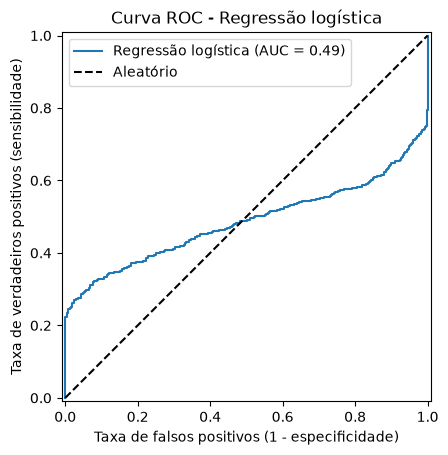

In [110]:
print("AUC:", roc_auc_score(y_teste, prob))

RocCurveDisplay.from_estimator(logit, X_teste, y_teste, name="Regressão logística")

# Diagonal de referência: classificador aleatório (AUC = 0.5)
plt.plot([0, 1], [0, 1], "k--", label="Aleatório")

plt.xlabel("Taxa de falsos positivos (1 - especificidade)")
plt.ylabel("Taxa de verdadeiros positivos (sensibilidade)")
plt.title("Curva ROC - Regressão logística")
plt.legend()
plt.show()

## 3.2 Árvore de Decisão

In [111]:
# Calcula as probabilidades de cada amostra para a classe 1
prob_arvore = decision_tree.predict_proba(X_teste)[:, 1]

# Definindo o corte (threshold) como 0.5
threshold = 0.5
classificador_arvore = (prob_arvore >= threshold).astype(int)

In [112]:
print("Matriz de Confusão")
print(confusion_matrix(y_teste, classificador_arvore))

print("\n")

print("Acurácia:", accuracy_score(y_teste, classificador_arvore))

# Precision: dos que o modelo previu como 1, quantos realmente são 1 -> VP / (VP + FP)
print("Precision:", precision_score(y_teste, classificador_arvore, zero_division=0))

# Recall (sensibilidade): dos que realmente são 1, quantos o modelo acertou -> VP / (VP + FN)
print("Recall:", recall_score(y_teste, classificador_arvore, zero_division=0))

Matriz de Confusão
[[344  44]
 [ 56 556]]


Acurácia: 0.9
Precision: 0.9266666666666666
Recall: 0.9084967320261438


AUC: 0.8975473350852368


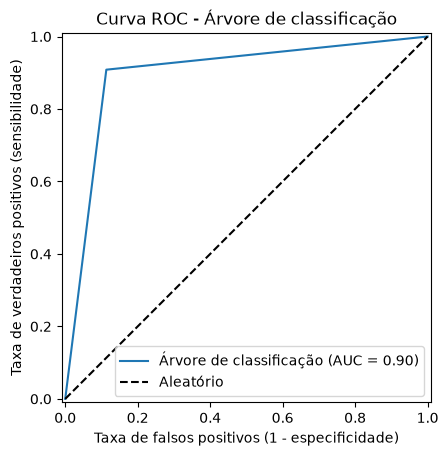

In [113]:
print("AUC:", roc_auc_score(y_teste, prob_arvore))

RocCurveDisplay.from_estimator(decision_tree, X_teste, y_teste, name="Árvore de classificação")

# Diagonal de referência: classificador aleatório (AUC = 0.5)
plt.plot([0, 1], [0, 1], "k--", label="Aleatório")

plt.xlabel("Taxa de falsos positivos (1 - especificidade)")
plt.ylabel("Taxa de verdadeiros positivos (sensibilidade)")
plt.title("Curva ROC - Árvore de classificação")
plt.legend()
plt.show()